In [2]:
import numpy as np
import pandas as pd
import math

In [3]:
# import synthetic landscape

data_folder = ''

lscape_name_notxt = 'FERM_zone0'

img_folder = '' + lscape_name_notxt + '/'

synscape = pd.read_csv(data_folder + lscape_name_notxt + '.txt', sep=' ')
print(synscape.shape)
print(synscape.columns)

(211229, 33)
Index(['xpos', 'ypos', 'zpos', 'tens', 'fric', 'coh', 'C:Tau', 'ssr', 'ssi',
       'smax', 'smid', 'smin', 'sxx', 'sxy', 'sxz', 'syy', 'syz', 'szz', 'vsi',
       'vsr', 'xxr', 'yyr', 'zzr', 'xyr', 'yzr', 'xzr', 'xxi', 'yyi', 'zzi',
       'xyi', 'yzi', 'xzi', 'diff-str'],
      dtype='object')


In [4]:
# investigate the data structure

print("spatial ranges")
print(f"xpos: {synscape['xpos'].min():.2f} to {synscape['xpos'].max():.2f}")
print(f"ypos: {synscape['ypos'].min():.2f} to {synscape['ypos'].max():.2f}")
print(f"zpos: {synscape['zpos'].min():.2f} to {synscape['zpos'].max():.2f}")

print(f"\nunique x: {synscape['xpos'].nunique()}")
print(f"unique y: {synscape['ypos'].nunique()}")
print(f"unique z: {synscape['zpos'].nunique()}")

print(f"\ntotal points: {len(synscape)}")
print(f"unique z * unique y * unique x would be: "
      f"{synscape['xpos'].nunique() * synscape['ypos'].nunique() * synscape['zpos'].nunique()}")

spatial ranges
xpos: 24.93 to 4981.94
ypos: 24.38 to 4923.50
zpos: -3748.31 to 963.20

unique x: 38159
unique y: 18504
unique z: 152577

total points: 211229
unique z * unique y * unique x would be: 107733724988472


In [5]:
# find surface elevation at each coarse bin
bin_size = 60

synscape['xbin'] = (synscape['xpos'] // bin_size).astype(int)
synscape['ybin'] = (synscape['ypos'] // bin_size).astype(int)

# surface = max zpos per bin
surface_z = synscape.groupby(['xbin','ybin'])['zpos'].max().reset_index()
surface_z.columns = ['xbin', 'ybin', 'z_surface']

# merge surface elevation back
synscape = synscape.merge(surface_z, on=['xbin','ybin'], how='left')

# depth below surface
synscape['depth_below_surface'] = synscape['z_surface'] - synscape['zpos']

# select points within 50 units below surface
depth_band = 50
surface_layer = synscape[synscape['depth_below_surface'] <= depth_band].copy()

print(f"surface layer points (within {depth_band} units of surface): {len(surface_layer)}")
print(f"depth_below_surface range: {surface_layer['depth_below_surface'].min():.2f} to {surface_layer['depth_below_surface'].max():.2f}")
print(f"unique bins covered: {surface_layer.groupby(['xbin','ybin']).ngroups}")

surface layer points (within 50 units of surface): 12165
depth_below_surface range: 0.00 to 50.00
unique bins covered: 6838


In [6]:
target_cols = ['coh', 'fric', 'tens', 'C:Tau',
               'sxx', 'sxy', 'sxz', 'syy', 'syz', 'szz',
               'smax', 'smid', 'smin']

# average within each bin
grid_df = surface_layer.groupby(['xbin', 'ybin'])[target_cols].mean().reset_index()

# add bin center coordinates
grid_df['x'] = grid_df['xbin'] * bin_size + bin_size / 2
grid_df['y'] = grid_df['ybin'] * bin_size + bin_size / 2

print(f"grid points: {len(grid_df)}")
print(f"x range: {grid_df['x'].min():.1f} to {grid_df['x'].max():.1f}")
print(f"y range: {grid_df['y'].min():.1f} to {grid_df['y'].max():.1f}")
print(f"\nC:Tau stats:")
print(grid_df['C:Tau'].describe())
print(f"\ncohesion stats:")
print(grid_df['coh'].describe())

grid points: 6838
x range: 30.0 to 5010.0
y range: 30.0 to 4950.0

C:Tau stats:
count    6838.000000
mean        1.593834
std         1.045658
min         0.000000
25%         1.052694
50%         1.253785
75%         1.774699
max        10.000000
Name: C:Tau, dtype: float64

cohesion stats:
count    6.838000e+03
mean     8.440540e+05
std      5.267815e+05
min      1.000000e+05
25%      3.737970e+05
50%      8.902406e+05
75%      1.253252e+06
max      1.899530e+06
Name: coh, dtype: float64


In [7]:
from scipy.interpolate import griddata

# determine grid dimensions
side = int(np.sqrt(len(grid_df)))
print(f"approximate grid side: {side} ({side**2} vs {len(grid_df)} points)")

x_grid = np.linspace(grid_df['x'].min(), grid_df['x'].max(), side)
y_grid = np.linspace(grid_df['y'].min(), grid_df['y'].max(), side)
xx, yy = np.meshgrid(x_grid, y_grid)
points = grid_df[['x', 'y']].values

grids = {}
for col in target_cols:
    cubic = griddata(points, grid_df[col].values, (xx, yy), method='cubic')
    nearest = griddata(points, grid_df[col].values, (xx, yy), method='nearest')
    filled = cubic.copy()
    filled[np.isnan(cubic)] = nearest[np.isnan(cubic)]
    grids[col] = filled
    print(f"{col}: shape={filled.shape}, NaNs={np.isnan(filled).sum()}, "
          f"range={np.nanmin(filled):.4f} to {np.nanmax(filled):.4f}")

approximate grid side: 82 (6724 vs 6838 points)
coh: shape=(82, 82), NaNs=0, range=-106146.4972 to 2066906.7116
fric: shape=(82, 82), NaNs=0, range=-0.5755 to 46.8009
tens: shape=(82, 82), NaNs=0, range=-14956.1786 to 201943.6970
C:Tau: shape=(82, 82), NaNs=0, range=-0.6133 to 9.4602
sxx: shape=(82, 82), NaNs=0, range=-46885980.4865 to 1956787.3342
sxy: shape=(82, 82), NaNs=0, range=-9883273.4814 to 7827688.6295
sxz: shape=(82, 82), NaNs=0, range=-10488324.5192 to 10695783.0383
syy: shape=(82, 82), NaNs=0, range=-38003085.0477 to 2843286.8329
syz: shape=(82, 82), NaNs=0, range=-8377692.7678 to 3997184.2315
szz: shape=(82, 82), NaNs=0, range=-29976755.5228 to 1580196.6536
smax: shape=(82, 82), NaNs=0, range=-47564213.0148 to 2777448.0866
smid: shape=(82, 82), NaNs=0, range=-38672982.3406 to 2070588.6991
smin: shape=(82, 82), NaNs=0, range=-29603481.0888 to 1532243.9635


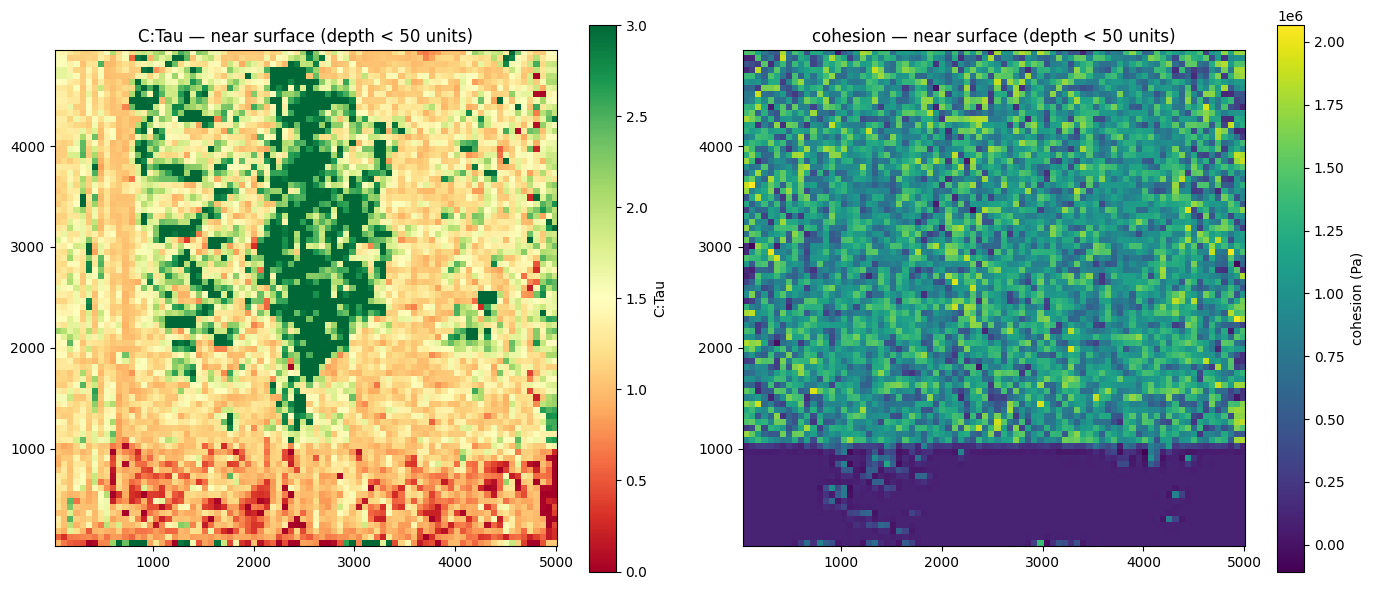

In [8]:
# visualize C:Tau
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

im0 = axes[0].imshow(grids['C:Tau'], cmap='RdYlGn', origin='lower',
                      extent=[x_grid.min(), x_grid.max(),
                               y_grid.min(), y_grid.max()],
                      vmin=0, vmax=3)
plt.colorbar(im0, ax=axes[0], label='C:Tau')
axes[0].set_title('C:Tau — near surface (depth < 50 units)')

im1 = axes[1].imshow(grids['coh'], cmap='viridis', origin='lower',
                      extent=[x_grid.min(), x_grid.max(),
                               y_grid.min(), y_grid.max()])
plt.colorbar(im1, ax=axes[1], label='cohesion (Pa)')
axes[1].set_title('cohesion — near surface (depth < 50 units)')

plt.tight_layout()
plt.show()

In [9]:
# cutting grids to remove artificial weak band
# find y index corresponding to y=1000
y_cut = np.searchsorted(y_grid, 1000)
print(f"cutting below y index {y_cut}, y={y_grid[y_cut]:.1f}")

grids_cropped = {col: arr[y_cut:, :] for col, arr in grids.items()}
xx_c = xx[y_cut:, :]
yy_c = yy[y_cut:, :]

print(f"cropped shape: {grids_cropped['C:Tau'].shape}")

cutting below y index 16, y=1001.9
cropped shape: (66, 82)


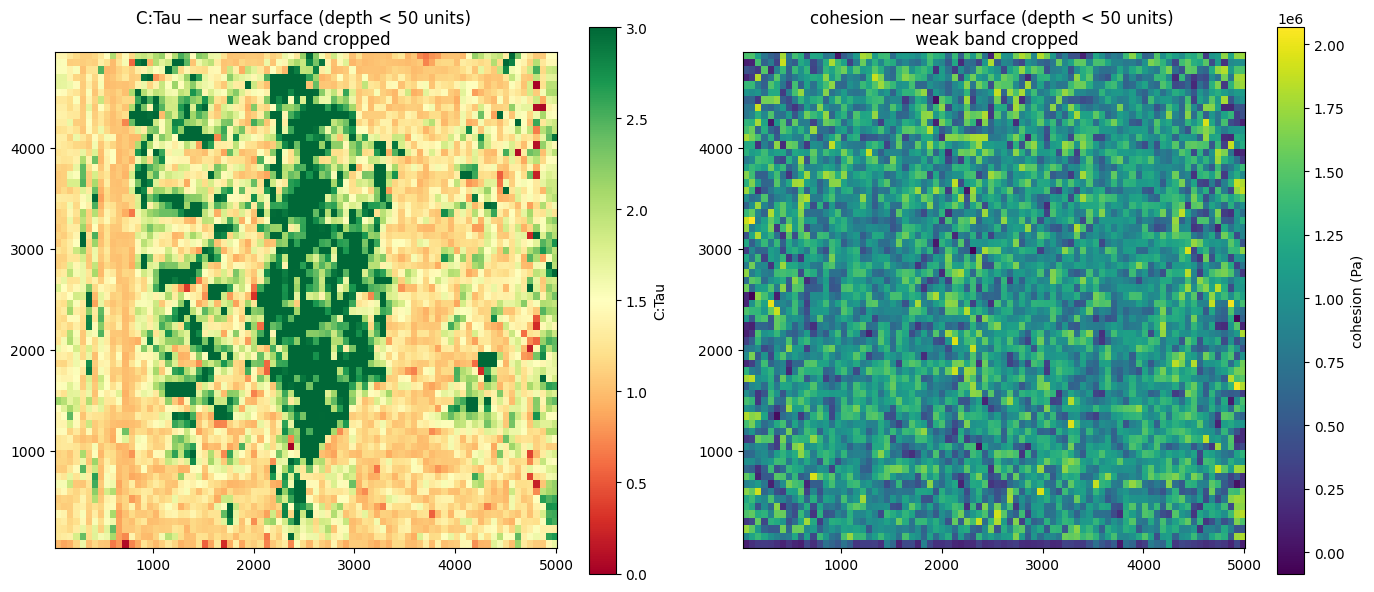

In [13]:
# visualize C:Tau
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

im0 = axes[0].imshow(grids_cropped['C:Tau'], cmap='RdYlGn', origin='lower',
                      extent=[x_grid.min(), x_grid.max(),
                               y_grid.min(), y_grid.max()],
                      vmin=0, vmax=3)
plt.colorbar(im0, ax=axes[0], label='C:Tau')
axes[0].set_title('C:Tau — near surface (depth < 50 units) \n weak band cropped')

im1 = axes[1].imshow(grids_cropped['coh'], cmap='viridis', origin='lower',
                      extent=[x_grid.min(), x_grid.max(),
                               y_grid.min(), y_grid.max()])
plt.colorbar(im1, ax=axes[1], label='cohesion (Pa)')
axes[1].set_title('cohesion — near surface (depth < 50 units) \n weak band cropped')

plt.tight_layout()
#plt.savefig("CTauDepth_cropped.png")
plt.show()

In [14]:
# save the grids
import numpy as np
import json
from datetime import date

np.savez('FERM_zone_surface_grids.npz', **grids_cropped,
         xx=xx_c, yy=yy_c)

meta = {
    'source': 'Copy_of_FERM_zone.txt',
    'depth_band': depth_band,
    'bin_size': bin_size,
    'grid_shape': [66, 82],
    'columns': target_cols,
    'date': str(date.today())
}
with open('FERM_zone_surface_grids_meta.json', 'w') as f:
    json.dump(meta, f, indent=2)

print("saved.")

saved.


In [16]:
## eigendecomposition on cropped stress grids ##
import math
import numpy as np

nrows, ncols = grids_cropped['C:Tau'].shape  # (66, 82)

# output arrays
sig_grid = np.zeros((nrows, ncols, 3))       # principal stresses
Svec_grid = np.zeros((nrows, ncols, 3, 3))  # principal directions

for i in range(nrows):
    for j in range(ncols):
        sigma = np.array([
            [grids_cropped['sxx'][i,j], grids_cropped['sxy'][i,j], grids_cropped['sxz'][i,j]],
            [grids_cropped['sxy'][i,j], grids_cropped['syy'][i,j], grids_cropped['syz'][i,j]],
            [grids_cropped['sxz'][i,j], grids_cropped['syz'][i,j], grids_cropped['szz'][i,j]]
        ])
        eigenvalues, eigenvectors = np.linalg.eigh(sigma)
        sig_grid[i, j, :] = eigenvalues
        Svec_grid[i, j, :, :] = eigenvectors.T

print(f"sig_grid shape: {sig_grid.shape}")
print(f"Svec_grid shape: {Svec_grid.shape}")
print(f"sig1 range: {sig_grid[:,:,0].min():.4e} to {sig_grid[:,:,0].max():.4e}")
print(f"sig3 range: {sig_grid[:,:,2].min():.4e} to {sig_grid[:,:,2].max():.4e}")

# spot check unit vectors
norms = np.sqrt((Svec_grid[33, 41, :, :]**2).sum(axis=1))
print(f"spot check eigenvector norms at center: {norms}")

sig_grid shape: (66, 82, 3)
Svec_grid shape: (66, 82, 3, 3)
sig1 range: -4.7925e+07 to 8.9574e+05
sig3 range: -2.9446e+07 to 1.8362e+06
spot check eigenvector norms at center: [1. 1. 1.]


In [17]:
from collections import defaultdict

def round_half_away(x):
    eps = 1e-9
    return int(math.floor(abs(x) + 0.5 + eps) * (1 if x >= 0 else -1))

def build_stress_graph(Svec_grid, sig_grid, eig_idx, nrows, ncols):
    """Build edge list from principal stress direction eig_idx (0=S1, 2=S3)."""
    
    # horizontal projection magnitudes for normalization
    Sx = Svec_grid[:, :, eig_idx, 0]
    Sy = Svec_grid[:, :, eig_idx, 1]
    horiz_mag = np.sqrt(Sx**2 + Sy**2)
    max_horiz = horiz_mag.max()
    
    directed_edges = {}
    for i in range(nrows):
        for j in range(ncols):
            hm = horiz_mag[i, j]
            if hm < 0.5:
                continue
            di = round_half_away(Svec_grid[i, j, eig_idx, 1])
            dj = round_half_away(Svec_grid[i, j, eig_idx, 0])
            if di == 0 and dj == 0:
                continue
            ni, nj = i + di, j + dj
            if ni < 0 or ni >= nrows or nj < 0 or nj >= ncols:
                continue
            directed_edges[(i, j, ni, nj)] = hm / max_horiz

    # symmetrize
    sym = {}
    for (i, j, ni, nj), w in directed_edges.items():
        key = (min((i,j),(ni,nj)), max((i,j),(ni,nj)))
        if key not in sym:
            sym[key] = []
        sym[key].append(w)
    
    return {k: np.mean(v) for k, v in sym.items()}

In [19]:
# build S1 and S3 graphs
edges_S1 = build_stress_graph(Svec_grid, sig_grid, 0, nrows, ncols)
edges_S3 = build_stress_graph(Svec_grid, sig_grid, 2, nrows, ncols)

# combine
combined_edges = {}
for key, w in edges_S1.items():
    combined_edges[key] = {'weight': w, 'source': 'S1'}
for key, w in edges_S3.items():
    if key in combined_edges:
        combined_edges[key] = {
            'weight': max(combined_edges[key]['weight'], w),
            'source': 'both'}
    else:
        combined_edges[key] = {'weight': w, 'source': 'S3'}

# degree
degree = defaultdict(float)
for ((i,j),(ni,nj)), attr in combined_edges.items():
    degree[(i,j)] += attr['weight']
    degree[(ni,nj)] += attr['weight']

print(f"S1 edges: {len(edges_S1)}")
print(f"S3 edges: {len(edges_S3)}")
print(f"combined edges: {len(combined_edges)}")
n_isolated = sum(degree[(i,j)] == 0 
                 for i in range(nrows) for j in range(ncols))
print(f"isolated nodes: {n_isolated}")

S1 edges: 3720
S3 edges: 4205
combined edges: 7352
isolated nodes: 4


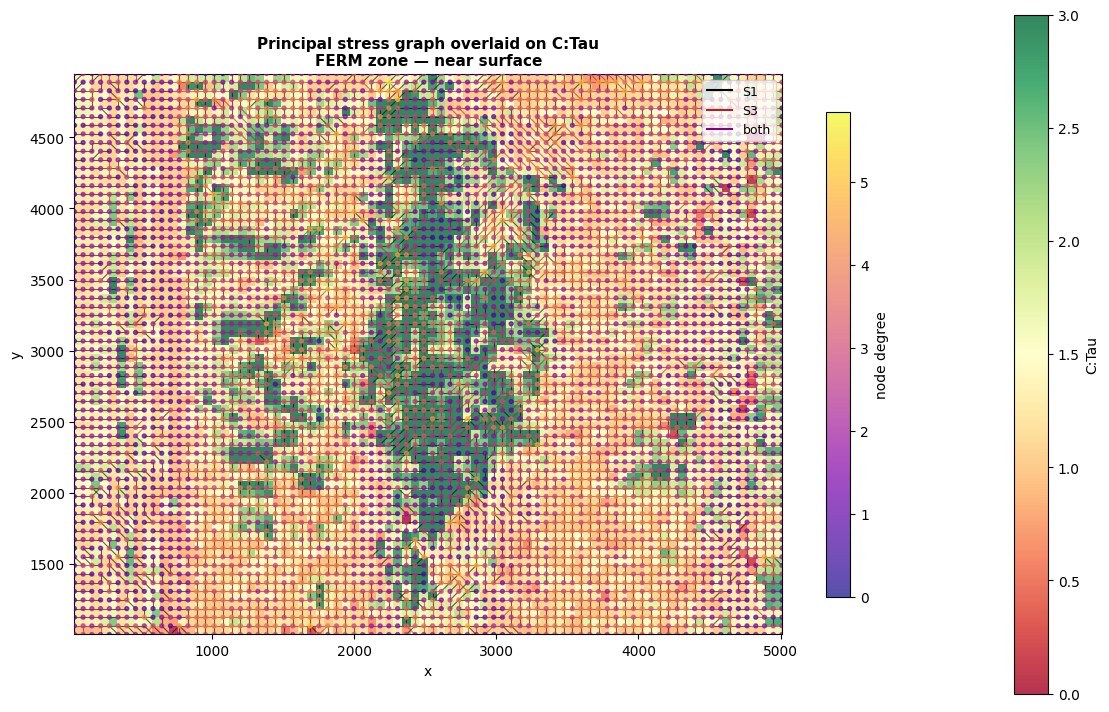

In [25]:
import matplotlib.pyplot as plt
import matplotlib.collections as mc

fig, ax = plt.subplots(figsize=(12, 10))

# C:Tau background
im = ax.imshow(grids_cropped['C:Tau'], cmap='RdYlGn', origin='lower',
               extent=[xx_c.min(), xx_c.max(), yy_c.min(), yy_c.max()],
               vmin=0, vmax=3, alpha=0.8)
plt.colorbar(im, ax=ax, shrink=0.7, label='C:Tau')

# draw edges
lines = []
colors = []
for ((i,j),(ni,nj)), attr in combined_edges.items():
    x0, y0 = xx_c[i,j], yy_c[i,j]
    x1, y1 = xx_c[ni,nj], yy_c[ni,nj]
    lines.append([(x0,y0),(x1,y1)])
    colors.append({'S1':'black','S3':'firebrick','both':'purple'}[attr['source']])

lc = mc.LineCollection(lines, colors=colors, linewidths=0.8,
                        alpha=0.6, zorder=2)
ax.add_collection(lc)

# nodes colored by degree
node_x = [xx_c[i,j] for i in range(nrows) for j in range(ncols)]
node_y = [yy_c[i,j] for i in range(nrows) for j in range(ncols)]
node_deg = [degree[(i,j)] for i in range(nrows) for j in range(ncols)]

sc = ax.scatter(node_x, node_y, c=node_deg, cmap='plasma',
    s=8, zorder=3, alpha=0.7)
plt.colorbar(sc, ax=ax, shrink=0.5, label='node degree')

from matplotlib.lines import Line2D
legend_elements = [
    Line2D([0],[0], color='black', label='S1'),
    Line2D([0],[0], color='firebrick', label='S3'),
    Line2D([0],[0], color='purple', label='both')
]
ax.legend(handles=legend_elements, loc='upper right', fontsize=9)

ax.set_title('Principal stress graph overlaid on C:Tau\nFERM zone — near surface',
             fontsize=11, fontweight='bold')
ax.set_xlabel('x')
ax.set_ylabel('y')
plt.tight_layout()
plt.savefig('StressGraphCTau.png')
plt.show()